In [1]:
import sys
print(sys.executable)

d:\CCA3-Computer-Vision\.venv\Scripts\python.exe


In [2]:
import sys
import cv2
import numpy as np
import matplotlib.pyplot as plt
import skimage
import torch
import ultralytics

print("Python Path:", sys.executable)
print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)
print("PyTorch Version:", torch.__version__)

print("All libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Python Path: d:\CCA3-Computer-Vision\.venv\Scripts\python.exe
OpenCV Version: 4.14.0
NumPy Version: 2.5.4
PyTorch Version: 2.15.0+cpu
All libraries imported successfully!


# CCA 3: Computer Vision Assignment

## Task 1: Image Restoration and Segmentation

**Unit:** Unit 3  
**Programming Language:** Python  
**Libraries:** OpenCV, NumPy, Matplotlib, scikit-image

### 1. Introduction

Image restoration and segmentation are important techniques in computer vision. Image restoration focuses on reducing noise and improving image quality, while image segmentation separates an image into meaningful regions for further analysis.

In this task, image processing techniques will be implemented using Python and OpenCV. Different restoration methods will be applied to a photograph, and their performance will be evaluated using image quality metrics.

### 2. Objectives

1. Generate Gaussian noise and salt-and-pepper noise.
2. Apply median filtering and Gaussian filtering.
3. Evaluate restored images using PSNR and SSIM.
4. Convert images into binary images using thresholding.
5. Perform erosion, dilation, opening and closing.
6. Apply Canny edge detection.
7. Perform watershed segmentation.
8. Compare the results of different image processing techniques.

### 3. Expected Outcomes

The task will generate noisy images, restored images, binary masks, morphological outputs, edge maps and watershed segmentation results. The effectiveness of the implemented techniques will be compared using visual observations and appropriate measurements.

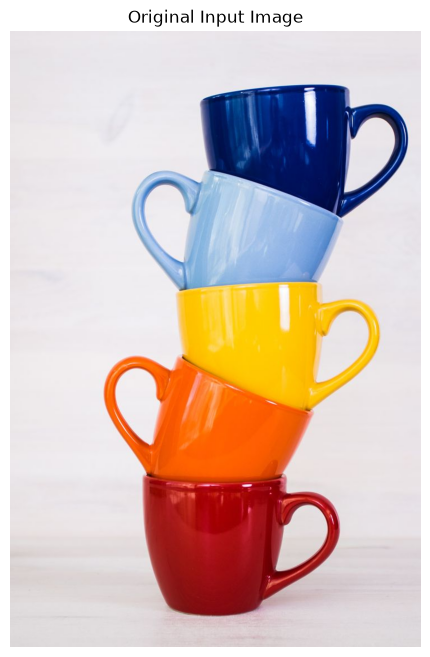

Image loaded successfully!
Image dimensions: (1104, 736, 3)


In [7]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

# Project dataset paths
IMAGE_PATH = Path("dataset/images/original.jpg")

# Load original image
original_image = cv2.imread(str(IMAGE_PATH))

if original_image is None:
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

# Convert BGR to RGB
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

# Display image
plt.figure(figsize=(8, 8))
plt.imshow(original_image)
plt.title("Original Input Image")
plt.axis("off")
plt.show()

print("Image loaded successfully!")
print("Image dimensions:", original_image.shape)

## Experiment 1: Gaussian Noise Generation

### Objective
To introduce Gaussian noise into the original image and observe how random pixel variations affect image quality.

### Theory
Gaussian noise is a type of image noise that follows a normal distribution. It introduces random variations in pixel intensity.

In this experiment, Gaussian noise will be generated using NumPy and added to the original photograph. The noisy result will be compared visually with the clean image.


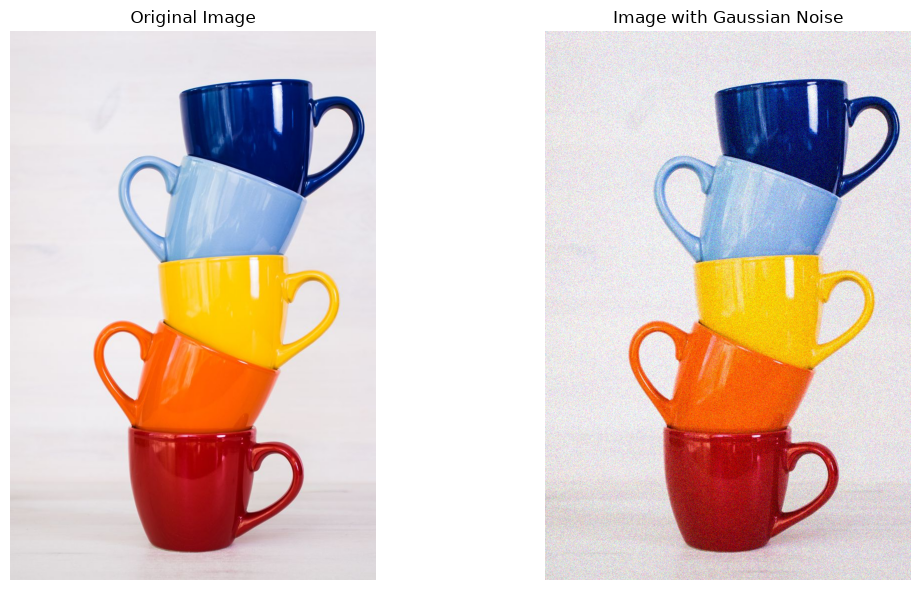

In [8]:
# Experiment 1: Gaussian Noise Generation

import numpy as np
import matplotlib.pyplot as plt

# Convert image into floating-point format
image_float = original_image.astype(np.float32) / 255.0

# Generate Gaussian noise
mean = 0
sigma = 0.08

gaussian_noise = np.random.normal(
    mean,
    sigma,
    image_float.shape
)

# Add noise to the original image
noisy_image = image_float + gaussian_noise

# Keep pixel values between 0 and 1
noisy_image = np.clip(noisy_image, 0, 1)

# Display original and noisy images
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(noisy_image)
plt.title("Image with Gaussian Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

### Observation

After applying Gaussian noise, random variations in pixel intensity were observed throughout the image. The noise affected both the background and the coloured cup regions. The original image appeared smooth, while the noisy image showed visible grain-like patterns.

### Result

Gaussian noise was successfully generated and added to the original image using NumPy. The resulting noisy image will be used in the next experiment to evaluate image restoration techniques.

## Experiment 2: Salt-and-Pepper Noise Generation

### Objective
To introduce salt-and-pepper noise into the original image and observe the effect of randomly distributed black and white pixels.

### Theory
Salt-and-pepper noise is a type of impulse noise. It introduces random white pixels (salt) and black pixels (pepper) into an image. It can affect image quality and reduce the visibility of important details.

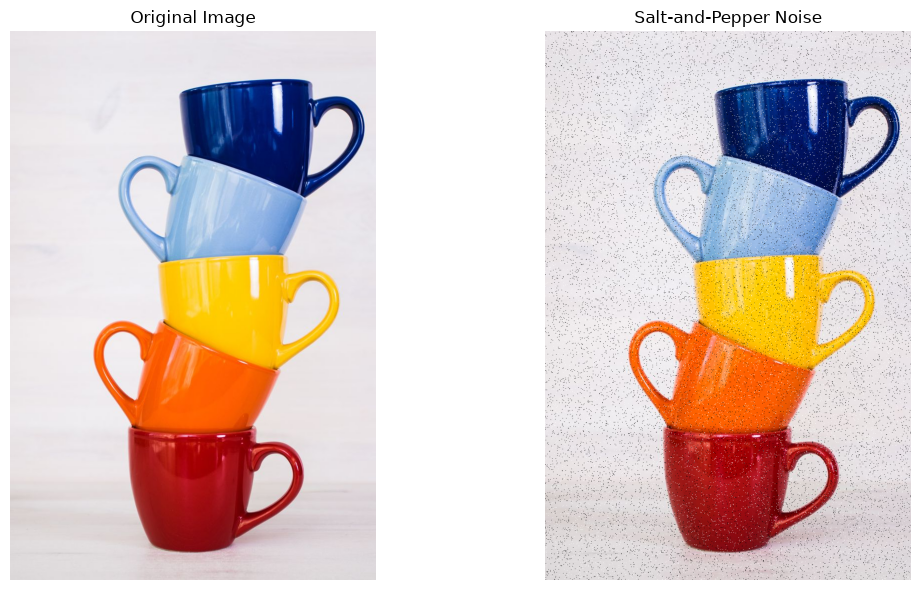

In [9]:
# Experiment 2: Salt-and-Pepper Noise

# Create a copy of the original image
salt_pepper_image = original_image.copy()

# Set noise percentage
noise_percentage = 0.04

# Generate random positions
random_map = np.random.random(original_image.shape[:2])

# Add pepper noise (black pixels)
salt_pepper_image[random_map < noise_percentage / 2] = 0

# Add salt noise (white pixels)
salt_pepper_image[random_map > 1 - noise_percentage / 2] = 255

# Display results
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(salt_pepper_image)
plt.title("Salt-and-Pepper Noise")
plt.axis("off")

plt.tight_layout()
plt.show()

## Experiment 3: Image Restoration Using Gaussian and Median Filters

### Objective
To reduce Gaussian and salt-and-pepper noise using Gaussian and median filtering techniques.

### Theory

**Gaussian Filter:** A linear smoothing filter that reduces noise by calculating a weighted average of neighbouring pixels. It is generally effective for Gaussian noise.

**Median Filter:** A nonlinear filter that replaces each pixel with the median value of its neighbourhood. It is particularly effective for removing salt-and-pepper noise while preserving edges.

### Restoration Comparison
Both filters will be applied to both noisy images to observe their effectiveness.

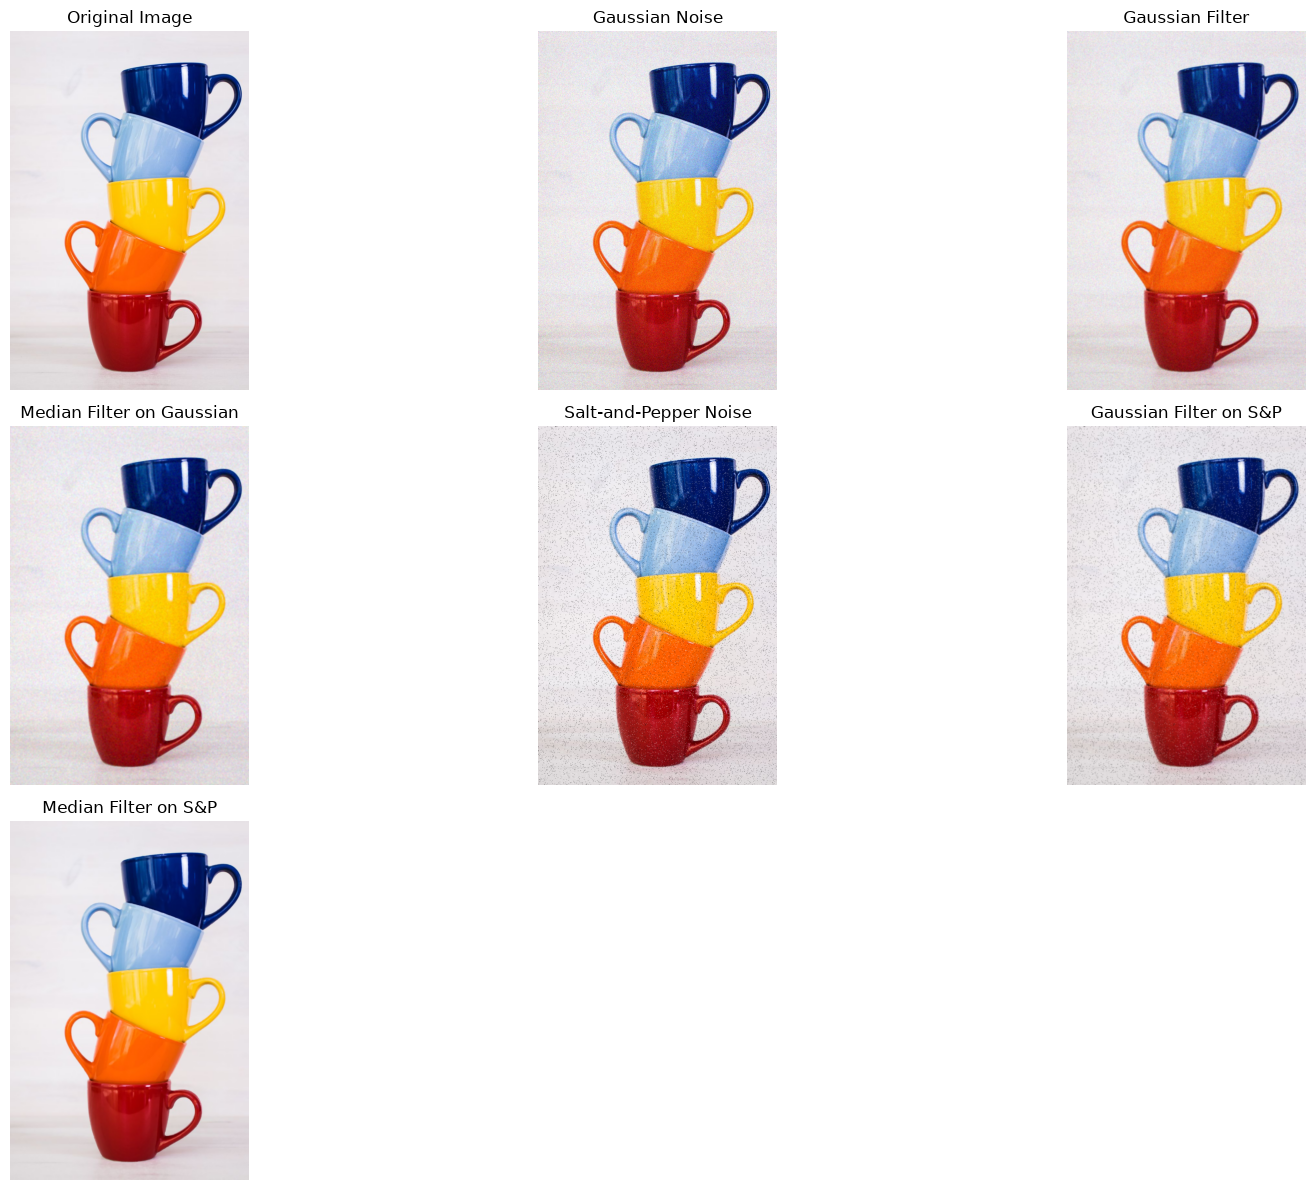

Image restoration completed successfully!


In [11]:
# Experiment 3: Image Restoration

# Convert Gaussian noisy image to 8-bit format
gaussian_noisy_uint8 = (
    np.clip(noisy_image, 0, 1) * 255
).astype(np.uint8)

# A. Restore Gaussian noise
gaussian_restored = cv2.GaussianBlur(
    gaussian_noisy_uint8,
    (5, 5),
    1.0
)

median_on_gaussian = cv2.medianBlur(
    gaussian_noisy_uint8,
    5
)

# B. Restore Salt-and-Pepper noise
gaussian_on_salt_pepper = cv2.GaussianBlur(
    salt_pepper_image,
    (5, 5),
    1.0
)

median_restored = cv2.medianBlur(
    salt_pepper_image,
    5
)

# Display all results
images = [
    (original_image, "Original Image"),
    (gaussian_noisy_uint8, "Gaussian Noise"),
    (gaussian_restored, "Gaussian Filter"),
    (median_on_gaussian, "Median Filter on Gaussian"),
    (salt_pepper_image, "Salt-and-Pepper Noise"),
    (gaussian_on_salt_pepper, "Gaussian Filter on S&P"),
    (median_restored, "Median Filter on S&P")
]

plt.figure(figsize=(16, 12))

for i, (img, title) in enumerate(images):
    plt.subplot(3, 3, i + 1)
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Image restoration completed successfully!")

In [12]:
from pathlib import Path

output_dir = Path("outputs/task1/restoration")
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(output_dir / "gaussian_restored.jpg"),
    cv2.cvtColor(gaussian_restored, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(output_dir / "median_restored.jpg"),
    cv2.cvtColor(median_restored, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(output_dir / "gaussian_on_salt_pepper.jpg"),
    cv2.cvtColor(gaussian_on_salt_pepper, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(output_dir / "median_on_salt_pepper.jpg"),
    cv2.cvtColor(median_restored, cv2.COLOR_RGB2BGR)
)

print("All restoration results saved successfully!")


All restoration results saved successfully!


## Experiment 4: Image Quality Evaluation using PSNR and SSIM

### Objective
To evaluate the quality of restored images by comparing them with the original image using Peak Signal-to-Noise Ratio (PSNR) and Structural Similarity Index (SSIM).

### Theory

**PSNR (Peak Signal-to-Noise Ratio):** PSNR measures the difference between the original and restored images. A higher PSNR value generally indicates lower reconstruction error.

**SSIM (Structural Similarity Index):** SSIM measures structural similarity between two images by considering luminance, contrast and structural information. Its value generally ranges from 0 to 1, with values closer to 1 indicating greater similarity.

Both metrics will be used to compare the effectiveness of Gaussian and median filtering techniques.

In [13]:
# Experiment 4: PSNR and SSIM Evaluation

from skimage.metrics import peak_signal_noise_ratio
from skimage.metrics import structural_similarity
import pandas as pd

# Calculate PSNR and SSIM
def evaluate_image(reference, restored, method_name):

    psnr_value = peak_signal_noise_ratio(
        reference,
        restored,
        data_range=255
    )

    ssim_value = structural_similarity(
        reference,
        restored,
        channel_axis=2,
        data_range=255
    )

    return {
        "Restoration Method": method_name,
        "PSNR (dB)": round(psnr_value, 2),
        "SSIM": round(ssim_value, 4)
    }


# Compare restored images with original image
results = []

results.append(
    evaluate_image(
        original_image,
        gaussian_noisy_uint8,
        "Gaussian Noise (Before Restoration)"
    )
)

results.append(
    evaluate_image(
        original_image,
        gaussian_restored,
        "Gaussian Filter on Gaussian Noise"
    )
)

results.append(
    evaluate_image(
        original_image,
        median_on_gaussian,
        "Median Filter on Gaussian Noise"
    )
)

results.append(
    evaluate_image(
        original_image,
        salt_pepper_image,
        "Salt-and-Pepper Noise (Before Restoration)"
    )
)

results.append(
    evaluate_image(
        original_image,
        gaussian_on_salt_pepper,
        "Gaussian Filter on Salt-and-Pepper"
    )
)

results.append(
    evaluate_image(
        original_image,
        median_restored,
        "Median Filter on Salt-and-Pepper"
    )
)

# Create comparison table
evaluation_df = pd.DataFrame(results)

display(evaluation_df)

print("PSNR and SSIM evaluation completed!")


,Restoration Method,PSNR (dB),SSIM
0,Gaussian Noise (Before Restoration),22.83,0.2271
1,Gaussian Filter on Gaussian Noise,31.47,0.7310
2,Median Filter on Gaussian Noise,31.90,0.7730
3,Salt-and-Pepper Noise (Before Restoration),17.94,0.3687
4,Gaussian Filter on Salt-and-Pepper,27.61,0.5926
5,Median Filter on Salt-and-Pepper,36.82,0.9768


PSNR and SSIM evaluation completed!


### Experimental Observations

The PSNR and SSIM values were calculated to evaluate the effectiveness of different image restoration techniques.

1. The Gaussian filter improved the PSNR from 22.83 dB to 31.47 dB for Gaussian noise.
2. The median filter achieved a slightly higher PSNR of 31.90 dB for Gaussian noise.
3. For salt-and-pepper noise, the median filter achieved a PSNR of 36.82 dB and an SSIM of 0.9768.
4. The Gaussian filter was less effective at removing salt-and-pepper noise compared with the median filter.

### Conclusion

The experiment demonstrates that both Gaussian and median filtering techniques improve image quality. However, median filtering produced the best restoration results for the salt-and-pepper noise in this experiment. The PSNR and SSIM measurements support the visual observations.

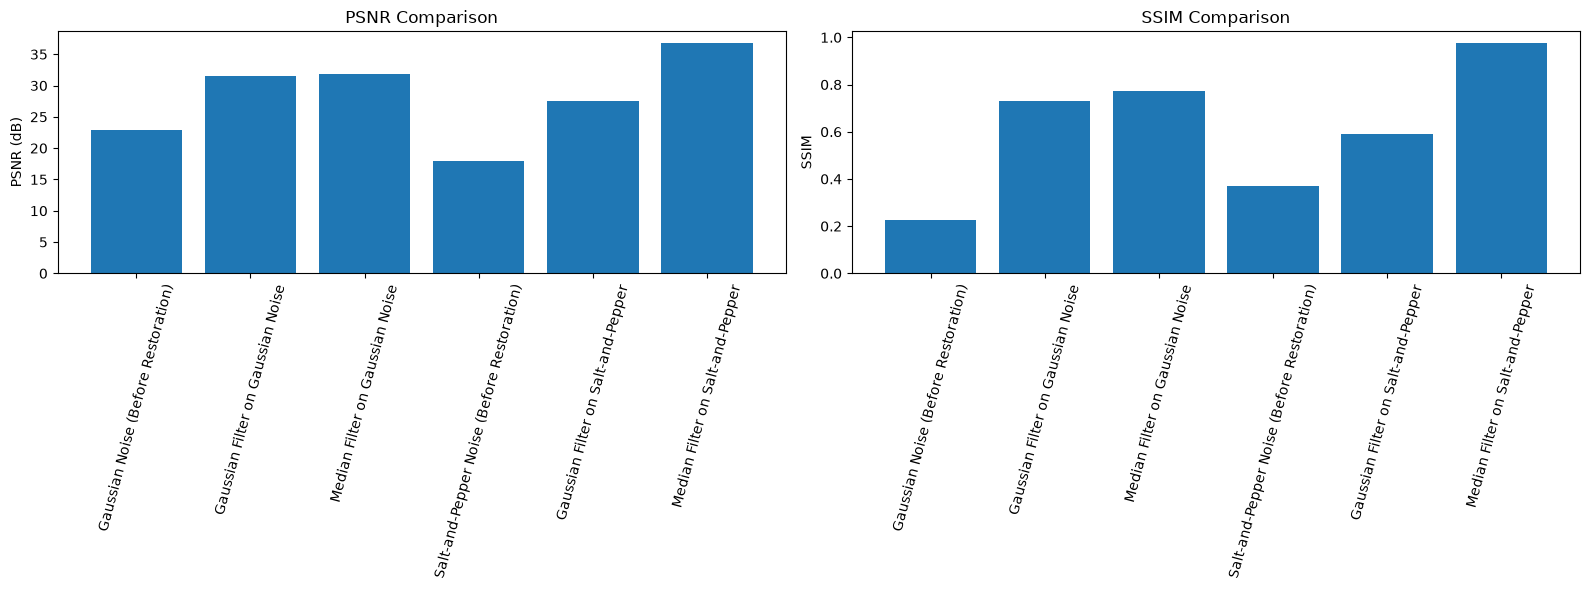

In [14]:
# Visual comparison of PSNR and SSIM

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PSNR comparison
axes[0].bar(
    evaluation_df["Restoration Method"],
    evaluation_df["PSNR (dB)"]
)
axes[0].set_title("PSNR Comparison")
axes[0].set_ylabel("PSNR (dB)")
axes[0].tick_params(axis="x", rotation=75)

# SSIM comparison
axes[1].bar(
    evaluation_df["Restoration Method"],
    evaluation_df["SSIM"]
)
axes[1].set_title("SSIM Comparison")
axes[1].set_ylabel("SSIM")
axes[1].tick_params(axis="x", rotation=75)

plt.tight_layout()
plt.show()

## Experiment 5: Image Thresholding

### Objective
To convert a grayscale image into binary images using different thresholding techniques.

### Theory

Image thresholding is a segmentation technique used to separate foreground objects from the background.

**1. Binary Thresholding:** Uses a fixed threshold value to classify pixels as black or white.

**2. Adaptive Thresholding:** Calculates different threshold values for local regions of the image. It is useful when illumination varies across the image.

**3. Otsu's Thresholding:** Automatically determines an optimal threshold value based on the grayscale intensity histogram.

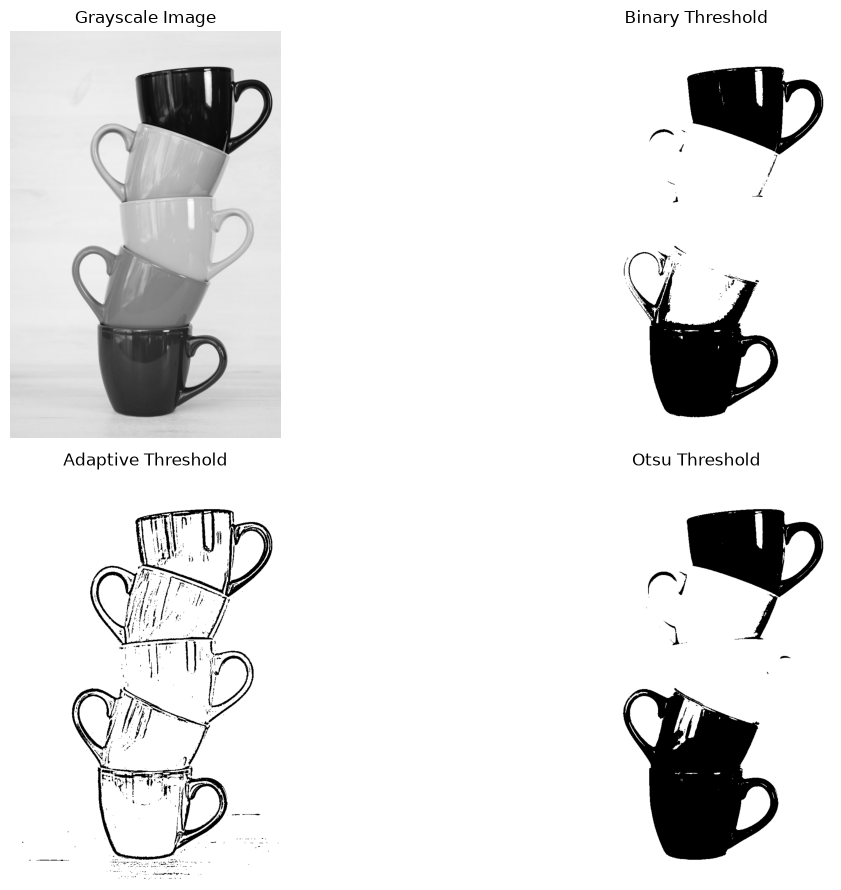

Otsu threshold value: 147.0
Thresholding completed successfully!


In [15]:
# Experiment 5: Image Thresholding

# Convert original RGB image to grayscale
gray_image = cv2.cvtColor(
    original_image,
    cv2.COLOR_RGB2GRAY
)

# 1. Binary thresholding
_, binary_threshold = cv2.threshold(
    gray_image,
    127,
    255,
    cv2.THRESH_BINARY
)

# 2. Adaptive thresholding
adaptive_threshold = cv2.adaptiveThreshold(
    gray_image,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21,
    5
)

# 3. Otsu thresholding
otsu_value, otsu_threshold = cv2.threshold(
    gray_image,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Display results
images = [
    (gray_image, "Grayscale Image"),
    (binary_threshold, "Binary Threshold"),
    (adaptive_threshold, "Adaptive Threshold"),
    (otsu_threshold, "Otsu Threshold")
]

plt.figure(figsize=(14, 9))

for i, (img, title) in enumerate(images):
    plt.subplot(2, 2, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Otsu threshold value:", otsu_value)
print("Thresholding completed successfully!")

In [16]:
# Save thresholding outputs

output_dir = Path("outputs/task1/segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(output_dir / "grayscale.jpg"),
    gray_image
)

cv2.imwrite(
    str(output_dir / "binary_threshold.jpg"),
    binary_threshold
)

cv2.imwrite(
    str(output_dir / "adaptive_threshold.jpg"),
    adaptive_threshold
)

cv2.imwrite(
    str(output_dir / "otsu_threshold.jpg"),
    otsu_threshold
)

print("Thresholding outputs saved successfully!")

Thresholding outputs saved successfully!


## Experiment 6: Morphological Operations

### Objective
To perform morphological operations on a binary image using erosion, dilation, opening and closing.

### Theory

Morphological operations are image processing techniques that modify the shape and structure of objects in a binary image.

**1. Erosion:** Reduces the boundaries of foreground objects.

**2. Dilation:** Expands the boundaries of foreground objects.

**3. Opening:** Performs erosion followed by dilation to remove small foreground noise.

**4. Closing:** Performs dilation followed by erosion to fill small gaps and holes.

These operations use a structuring element called a kernel.

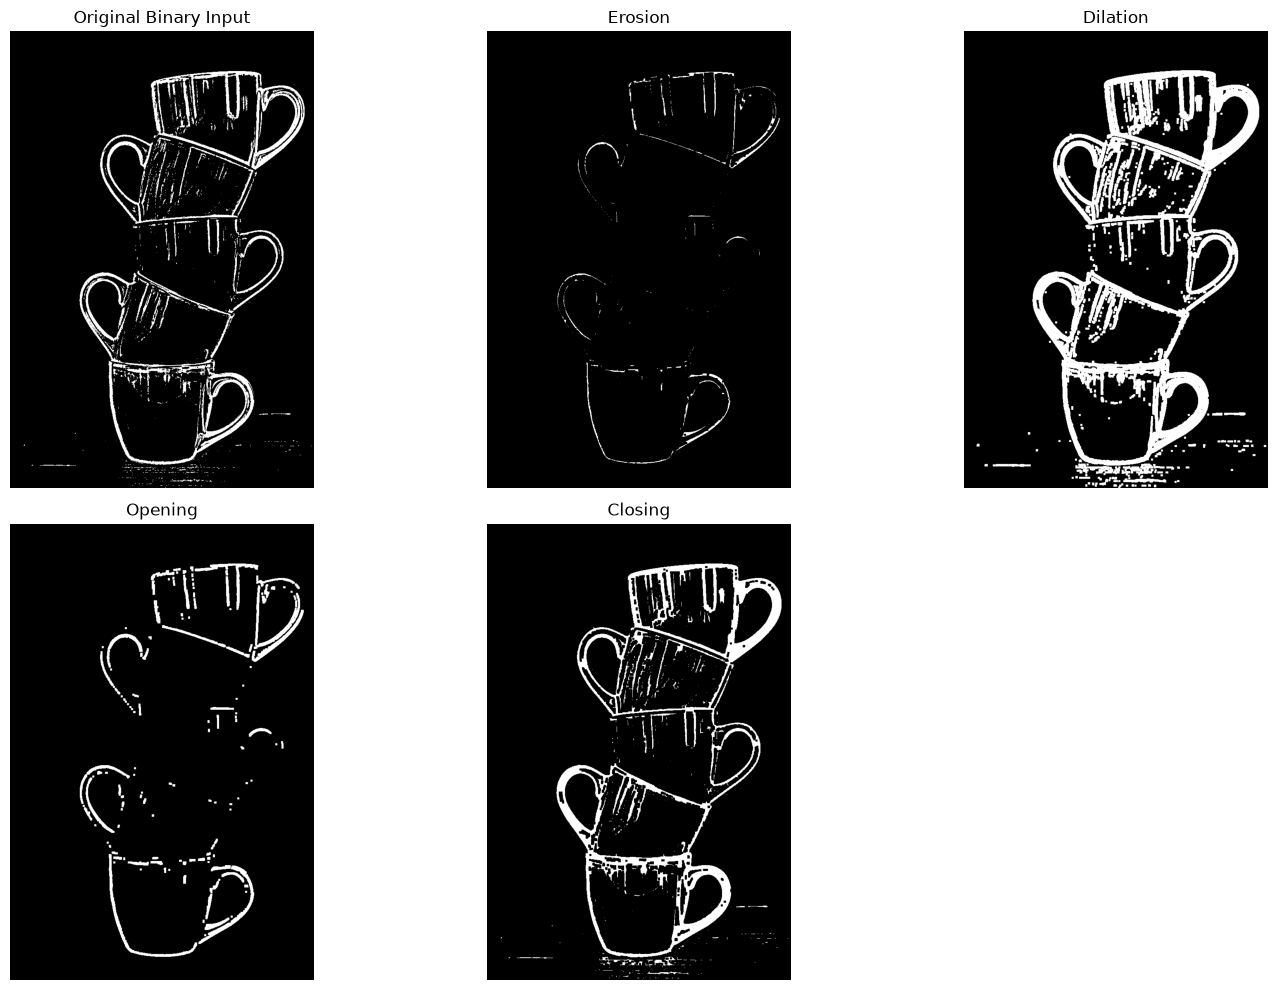

Morphological operations completed successfully!


In [17]:
# Experiment 6: Morphological Operations

# Use adaptive threshold and invert it
# This makes the dark outlines white foreground pixels
morph_input = cv2.bitwise_not(adaptive_threshold)

# Create a 5x5 structuring element
kernel = np.ones((5, 5), np.uint8)

# 1. Erosion
erosion = cv2.erode(
    morph_input,
    kernel,
    iterations=1
)

# 2. Dilation
dilation = cv2.dilate(
    morph_input,
    kernel,
    iterations=1
)

# 3. Opening
opening = cv2.morphologyEx(
    morph_input,
    cv2.MORPH_OPEN,
    kernel
)

# 4. Closing
closing = cv2.morphologyEx(
    morph_input,
    cv2.MORPH_CLOSE,
    kernel
)

# Display results
images = [
    (morph_input, "Original Binary Input"),
    (erosion, "Erosion"),
    (dilation, "Dilation"),
    (opening, "Opening"),
    (closing, "Closing")
]

plt.figure(figsize=(15, 10))

for i, (img, title) in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Morphological operations completed successfully!")

In [18]:
# Save morphological operation results

output_dir = Path("outputs/task1/segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

morph_results = {
    "morph_input": morph_input,
    "erosion": erosion,
    "dilation": dilation,
    "opening": opening,
    "closing": closing
}

for name, image in morph_results.items():
    cv2.imwrite(
        str(output_dir / f"{name}.jpg"),
        image
    )

print("Morphological outputs saved successfully!")

Morphological outputs saved successfully!


### Observations

The morphological operations were successfully applied to the binary image of stacked cups.

1. Erosion reduced the thickness of white foreground regions and removed some small details.
2. Dilation expanded the white regions and increased the thickness of object boundaries.
3. Opening removed some small foreground noise and thin details.
4. Closing connected nearby regions and filled some small gaps in the cup outlines.

### Result

All four morphological operations were implemented successfully using OpenCV. The experiment demonstrated how erosion, dilation, opening and closing modify the shape and structure of binary images.

## Experiment 7: Canny Edge Detection

### Objective
To detect the edges and boundaries of objects in an image using the Canny edge detection algorithm.

### Theory

Canny edge detection is an edge detection technique used in computer vision to identify significant intensity changes in an image.

The algorithm involves noise reduction, gradient calculation, non-maximum suppression and hysteresis thresholding.

It helps identify object boundaries and important structural details in an image.

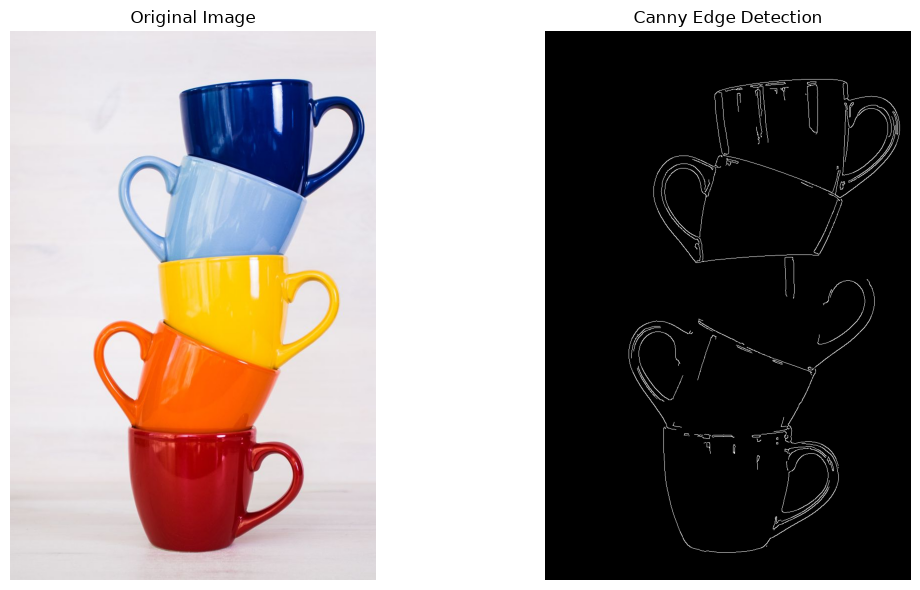

Canny edge detection completed successfully!


In [19]:
# Experiment 7: Canny Edge Detection

# Convert original image to grayscale
canny_gray = cv2.cvtColor(
    original_image,
    cv2.COLOR_RGB2GRAY
)

# Reduce noise before edge detection
blurred_image = cv2.GaussianBlur(
    canny_gray,
    (5, 5),
    1.0
)

# Apply Canny edge detection
canny_edges = cv2.Canny(
    blurred_image,
    50,
    150
)

# Display results
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(canny_edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Canny edge detection completed successfully!")

In [20]:
# Save Canny edge detection result

output_dir = Path("outputs/task1/segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(output_dir / "canny_edges.jpg"),
    canny_edges
)

print("Canny edge image saved successfully!")

Canny edge image saved successfully!


### Observations

Canny edge detection was successfully applied to the original stacked-cups image.

1. The algorithm detected the outer boundaries of the cups.
2. The handles and curved edges were clearly identified.
3. Some internal surface details and reflections were also detected.
4. A few boundaries were incomplete due to overlapping objects and similar intensity values.

### Result

The Canny edge detection algorithm successfully identified important edges and structural boundaries in the input image. Gaussian smoothing was applied before edge detection to reduce noise and improve the result.

## Experiment 8: Watershed Segmentation

### Objective
To segment an image into different regions using the watershed segmentation algorithm.

### Theory

Watershed is a region-based image segmentation technique. It treats the grayscale image as a topographic surface, where pixel intensity represents elevation.

The algorithm uses foreground and background markers to identify different regions. Watershed segmentation helps separate connected or overlapping objects by identifying their boundaries.

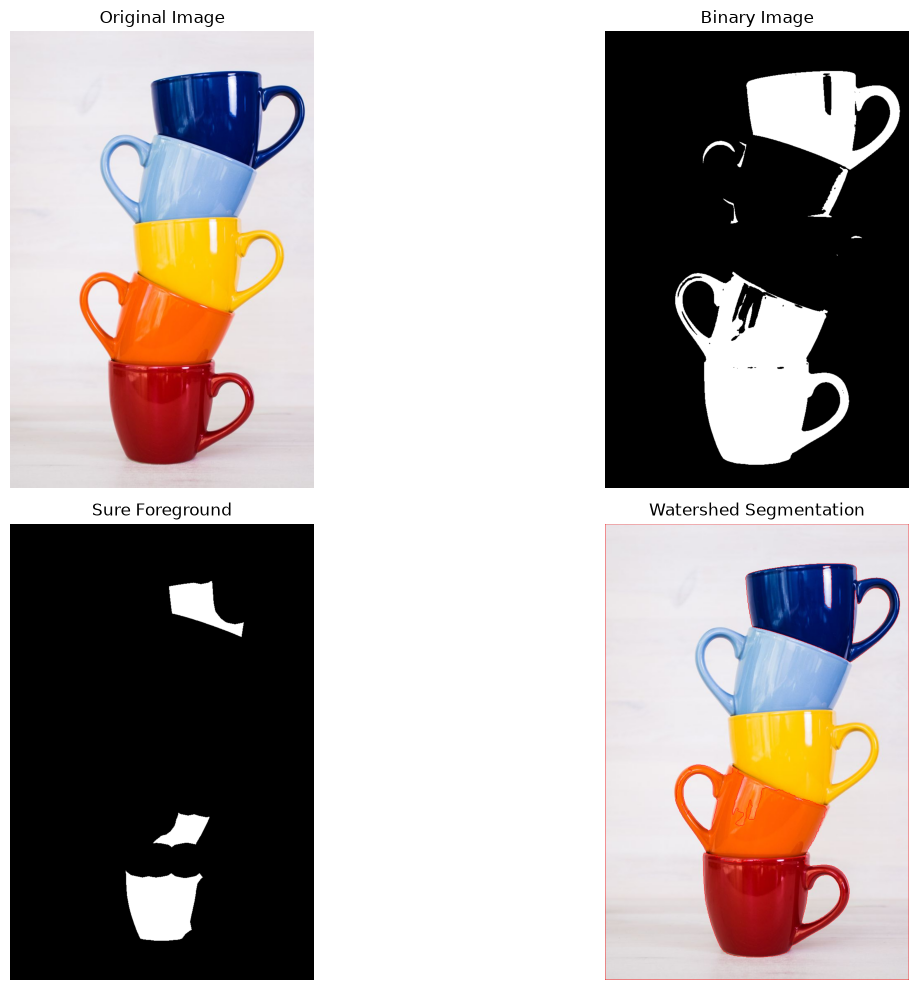

Watershed segmentation completed successfully!
Number of foreground marker labels: 3


In [21]:
# Experiment 8: Watershed Segmentation

# Convert original image to grayscale
watershed_gray = cv2.cvtColor(
    original_image,
    cv2.COLOR_RGB2GRAY
)

# Apply Gaussian blur
watershed_blur = cv2.GaussianBlur(
    watershed_gray,
    (5, 5),
    0
)

# Create binary image using Otsu thresholding
_, watershed_binary = cv2.threshold(
    watershed_blur,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Remove small noise using morphological opening
kernel = np.ones((3, 3), np.uint8)

opening_ws = cv2.morphologyEx(
    watershed_binary,
    cv2.MORPH_OPEN,
    kernel,
    iterations=2
)

# Identify background region
sure_bg = cv2.dilate(
    opening_ws,
    kernel,
    iterations=3
)

# Identify foreground region using distance transform
distance_transform = cv2.distanceTransform(
    opening_ws,
    cv2.DIST_L2,
    5
)

_, sure_fg = cv2.threshold(
    distance_transform,
    0.35 * distance_transform.max(),
    255,
    0
)

sure_fg = np.uint8(sure_fg)

# Identify unknown region
unknown = cv2.subtract(
    sure_bg,
    sure_fg
)

# Label foreground markers
_, markers = cv2.connectedComponents(sure_fg)

# Add one to all labels so background is not zero
markers = markers + 1

# Mark unknown regions as zero
markers[unknown == 255] = 0

# Apply watershed algorithm
watershed_image = original_image.copy()

markers = cv2.watershed(
    cv2.cvtColor(watershed_image, cv2.COLOR_RGB2BGR),
    markers
)

# Mark watershed boundaries in red
watershed_image[markers == -1] = [255, 0, 0]

# Display results
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(watershed_binary, cmap="gray")
plt.title("Binary Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(sure_fg, cmap="gray")
plt.title("Sure Foreground")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(watershed_image)
plt.title("Watershed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Watershed segmentation completed successfully!")
print("Number of foreground marker labels:", markers.max() - 1)


In [22]:
# Save watershed segmentation results

output_dir = Path("outputs/task1/segmentation")
output_dir.mkdir(parents=True, exist_ok=True)

cv2.imwrite(
    str(output_dir / "watershed_result.jpg"),
    cv2.cvtColor(watershed_image, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(output_dir / "watershed_binary.jpg"),
    watershed_binary
)

cv2.imwrite(
    str(output_dir / "watershed_foreground.jpg"),
    sure_fg
)

print("Watershed outputs saved successfully!")

Watershed outputs saved successfully!


### Observations

The watershed segmentation algorithm was successfully implemented using OpenCV.

1. The original image was converted into grayscale.
2. Otsu thresholding was used to generate a binary image.
3. Morphological opening was applied to reduce noise.
4. Distance transformation was used to identify sure foreground regions.
5. Background and foreground markers were generated and supplied to the watershed algorithm.
6. The resulting image displayed watershed boundaries in red.

The foreground markers did not identify all five cups separately. This affected the segmentation quality because the cups overlap and have similar foreground and background intensity characteristics.

### Result

Watershed segmentation was successfully executed. The experiment demonstrated marker-based image segmentation and showed that foreground marker selection plays an important role in separating objects.